<a href="https://colab.research.google.com/github/GHusergate/Colab-20102026/blob/main/20Oct2026_new844pm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Hello! My first Python program")
print("I am learning quantitative trading.")

Hello! My first Python program
I am learning quantitative trading.


In [2]:
%pip install yfinance pandas numpy matplotlib

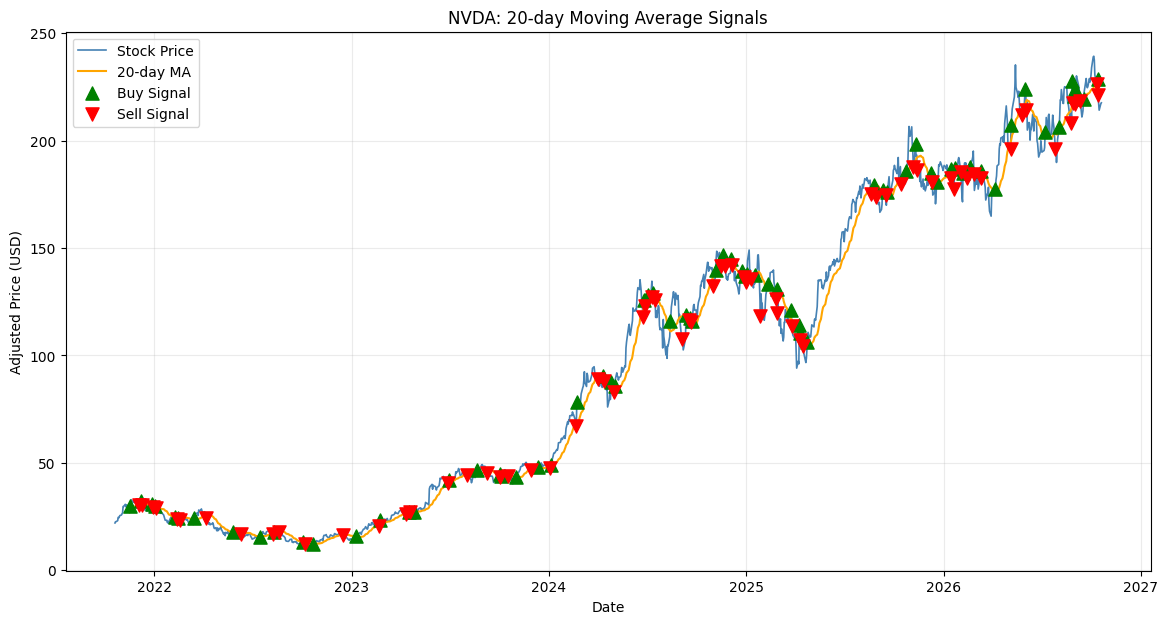


NVDA 最近5個交易日：


,Price,MA20,Signal
Date,,,
2026-10-14,221.300003,228.689501,不持有訊號
2026-10-15,217.229996,228.584001,不持有訊號
2026-10-16,214.130005,228.177001,不持有訊號
2026-10-19,217.089996,227.662501,不持有訊號
2026-10-20,217.546997,227.096351,不持有訊號


最新模型狀態： 不持有訊號


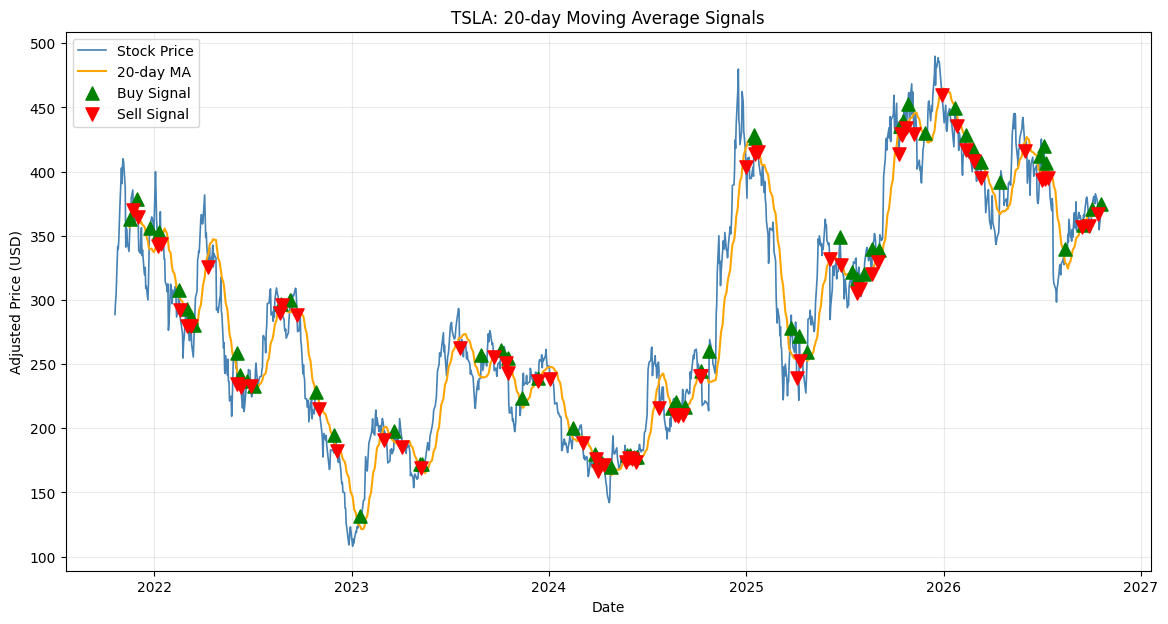


TSLA 最近5個交易日：


,Price,MA20,Signal
Date,,,
2026-10-14,367.160004,370.998999,不持有訊號
2026-10-15,362.440002,370.810999,不持有訊號
2026-10-16,354.720001,370.333499,不持有訊號
2026-10-19,368.059998,369.971500,不持有訊號
2026-10-20,374.619995,369.757500,持有訊號


最新模型狀態： 持有訊號


In [4]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

def show_signals(ticker):
    # 下載最近5年歷史股價
    df = yf.download(
        ticker,
        period="5y",
        auto_adjust=True,
        progress=False
    )

    if df.empty:
        print(f"{ticker}: 無法取得股價數據")
        return

    close = df["Close"].squeeze().dropna()

    # 計算20日移動平均線
    ma20 = close.rolling(window=20).mean()

    # 股價高於平均線：1；否則：0
    signal = (close > ma20).astype(int)

    # 只標記持倉狀態發生改變的日期
    change = signal.diff()

    buy_dates = close.index[change == 1]
    sell_dates = close.index[change == -1]

    # 繪圖
    plt.figure(figsize=(14, 7))
    plt.plot(close.index, close, label="Stock Price",
             color="steelblue", linewidth=1.2)
    plt.plot(ma20.index, ma20, label="20-day MA",
             color="orange", linewidth=1.5)

    # 買入訊號
    plt.scatter(
        buy_dates, close.loc[buy_dates],
        marker="^", color="green", s=90,
        label="Buy Signal", zorder=5
    )

    # 賣出訊號
    plt.scatter(
        sell_dates, close.loc[sell_dates],
        marker="v", color="red", s=90,
        label="Sell Signal", zorder=5
    )

    plt.title(f"{ticker}: 20-day Moving Average Signals")
    plt.xlabel("Date")
    plt.ylabel("Adjusted Price (USD)")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

    print(f"\n{ticker} 最近5個交易日：")
    result = pd.DataFrame({
        "Price": close,
        "MA20": ma20,
        "Signal": signal.map({
            1: "持有訊號",
            0: "不持有訊號"
        })
    })
    display(result.tail())

    print("最新模型狀態：",
          "持有訊號" if signal.iloc[-1] == 1
          else "不持有訊號")

# 分析兩隻股票
show_signals("NVDA")
show_signals("TSLA")


===== NVDA 回測結果 =====


,20日平均線策略,買入並持有
總回報,187.87%,886.34%
年化回報,23.55%,58.06%
最大回撤,-54.20%,-66.34%


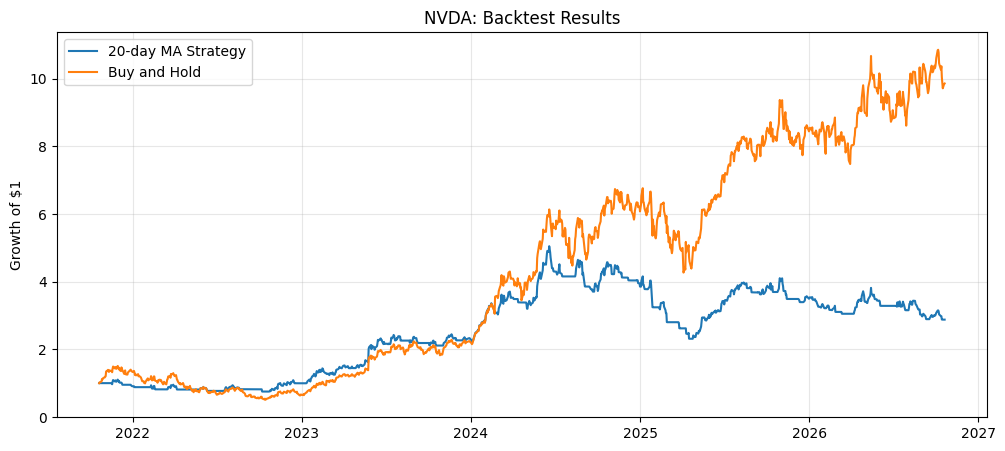

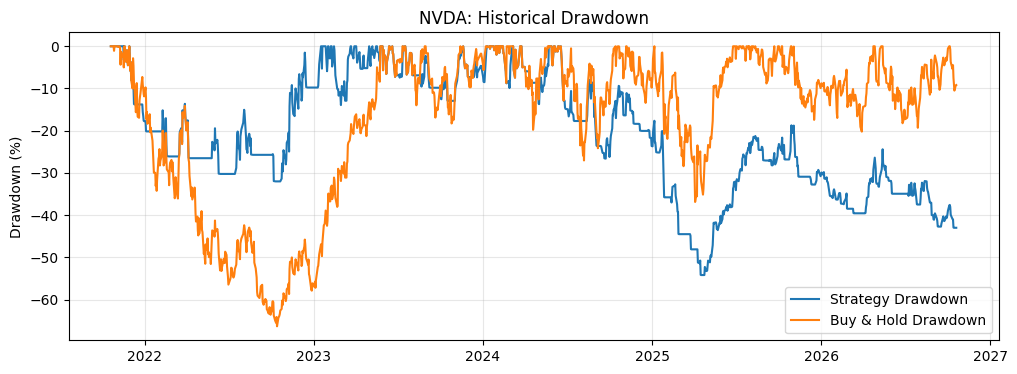


===== TSLA 回測結果 =====


,20日平均線策略,買入並持有
總回報,91.16%,29.54%
年化回報,13.84%,5.31%
最大回撤,-37.45%,-73.63%


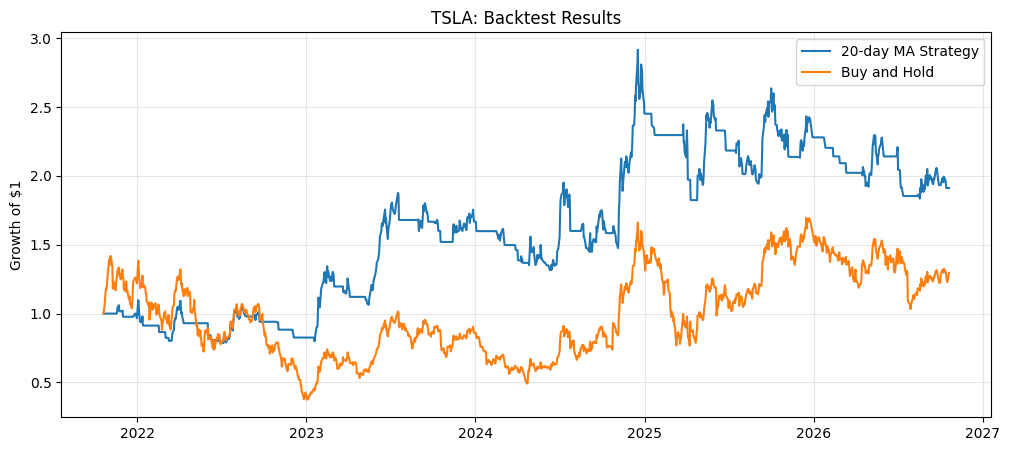

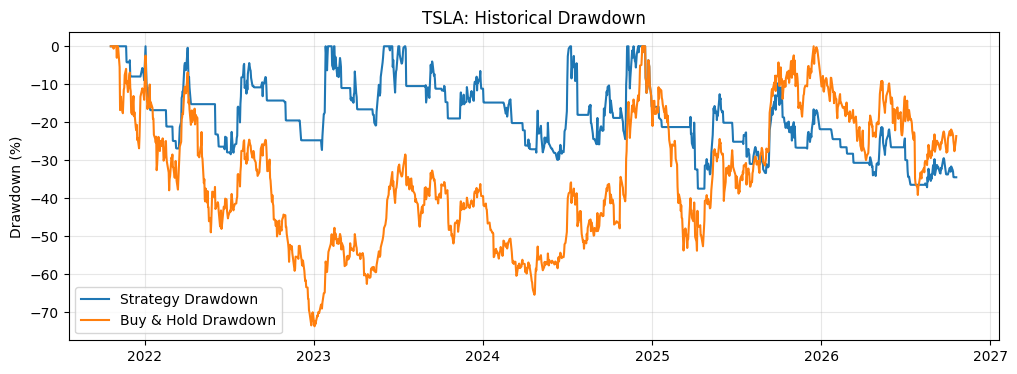

In [5]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def backtest(ticker, period="5y", cost=0.001):

    # 1. 下載歷史股價
    data = yf.Ticker(ticker).history(
        period=period,
        auto_adjust=True
    )

    if data.empty:
        print(f"{ticker}: 無法取得數據")
        return None

    close = data["Close"].dropna()

    # 2. 計算20日移動平均線
    ma20 = close.rolling(20).mean()

    # 股價高於20日平均線時產生持有訊號
    signal = (close > ma20).astype(int)

    # 訊號延後一天執行，避免偷看未來
    position = signal.shift(1).fillna(0)

    # 3. 計算每日股價回報
    daily_return = close.pct_change().fillna(0)

    # 4. 計算持倉變動及交易成本
    trades = position.diff().abs()
    trades.iloc[0] = position.iloc[0]
    trades = trades.fillna(0)

    # 假設每次買賣的單邊成本為0.1%
    trading_cost = trades * cost

    # 策略每日淨回報
    strategy_return = (
        position * daily_return - trading_cost
    )

    # 買入並持有：假設期初買入，並扣除一次買入成本
    buy_hold_return = daily_return.copy()
    buy_hold_return.iloc[0] = (
        (1 + buy_hold_return.iloc[0]) * (1 - cost) - 1
    )

    # 5. 計算累積資產曲線
    strategy_equity = (1 + strategy_return).cumprod()
    buy_hold_equity = (1 + buy_hold_return).cumprod()

    # 6. 計算總回報
    strategy_total = strategy_equity.iloc[-1] - 1
    buy_hold_total = buy_hold_equity.iloc[-1] - 1

    # 7. 計算最大回撤
    strategy_drawdown = (
        strategy_equity / strategy_equity.cummax() - 1
    )
    buy_hold_drawdown = (
        buy_hold_equity / buy_hold_equity.cummax() - 1
    )

    strategy_mdd = strategy_drawdown.min()
    buy_hold_mdd = buy_hold_drawdown.min()

    # 8. 計算年化回報
    years = (
        (close.index[-1] - close.index[0]).days / 365.25
    )

    strategy_cagr = (
        strategy_equity.iloc[-1] ** (1 / years) - 1
        if years > 0 else np.nan
    )
    buy_hold_cagr = (
        buy_hold_equity.iloc[-1] ** (1 / years) - 1
        if years > 0 else np.nan
    )

    # 9. 顯示結果
    results = pd.DataFrame({
        "20日平均線策略": [
            strategy_total,
            strategy_cagr,
            strategy_mdd
        ],
        "買入並持有": [
            buy_hold_total,
            buy_hold_cagr,
            buy_hold_mdd
        ]
    }, index=[
        "總回報",
        "年化回報",
        "最大回撤"
    ])

    print(f"\n===== {ticker} 回測結果 =====")
    display(results.style.format("{:.2%}"))

    # 10. 繪製資產曲線
    plt.figure(figsize=(12, 5))
    plt.plot(
        strategy_equity.index,
        strategy_equity,
        label="20-day MA Strategy"
    )
    plt.plot(
        buy_hold_equity.index,
        buy_hold_equity,
        label="Buy and Hold"
    )
    plt.title(f"{ticker}: Backtest Results")
    plt.ylabel("Growth of $1")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    # 11. 繪製回撤曲線
    plt.figure(figsize=(12, 4))
    plt.plot(
        strategy_drawdown.index,
        strategy_drawdown * 100,
        label="Strategy Drawdown"
    )
    plt.plot(
        buy_hold_drawdown.index,
        buy_hold_drawdown * 100,
        label="Buy & Hold Drawdown"
    )
    plt.title(f"{ticker}: Historical Drawdown")
    plt.ylabel("Drawdown (%)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    return results


# 分別測試 Nvidia 及 Tesla
nvda_results = backtest("NVDA")
tsla_results = backtest("TSLA")

正在分析：Nvidia (NVDA)
正在分析：Tesla (TSLA)
正在分析：Vanguard FTSE All-World Acc (VWRP.L)
正在分析：Vanguard S&P 500 Acc (VUAG.L)
正在分析：Xtrackers NASDAQ 100 Acc (XNAQ.L)
正在分析：SPDR S&P 500 Leaders Acc (SPPY.L)
  歷史數據不足，跳過。
正在分析：AST SpaceMobile (ASTS)
正在分析：Redwire (RDW)

===== 全部標的及策略比較 =====


,Asset,Ticker,MA Days,Strategy Return,Buy & Hold Return,Strategy CAGR,Buy & Hold CAGR,Strategy Max DD,Buy & Hold Max DD,Trade Events,Start Date,End Date
0,Nvidia,NVDA,20,187.87%,620.02%,23.96%,49.34%,-54.20%,-66.34%,138,2021-11-16,2026-10-20
1,Nvidia,NVDA,50,315.96%,634.94%,34.56%,51.49%,-33.47%,-62.70%,84,2021-12-30,2026-10-20
2,Nvidia,NVDA,100,336.02%,919.24%,37.71%,65.61%,-41.41%,-60.80%,61,2022-03-14,2026-10-20
3,Tesla,TSLA,20,91.16%,6.66%,14.07%,1.32%,-37.45%,-72.97%,134,2021-11-16,2026-10-20
4,Tesla,TSLA,50,-31.31%,5.10%,-7.52%,1.04%,-52.59%,-72.97%,97,2021-12-30,2026-10-20
5,Tesla,TSLA,100,-29.87%,46.79%,-7.42%,8.70%,-50.59%,-71.69%,62,2022-03-14,2026-10-20
6,Vanguard FTSE All-World Acc,VWRP.L,20,25.40%,61.48%,4.70%,10.22%,-13.79%,-17.64%,128,2021-11-16,2026-10-20
7,Vanguard FTSE All-World Acc,VWRP.L,50,15.39%,62.37%,3.03%,10.62%,-14.69%,-17.64%,86,2021-12-30,2026-10-20
8,Vanguard FTSE All-World Acc,VWRP.L,100,29.03%,77.78%,5.69%,13.30%,-16.30%,-17.64%,49,2022-03-11,2026-10-20
9,Vanguard S&P 500 Acc,VUAG.L,20,5.80%,74.06%,1.15%,11.92%,-20.48%,-20.88%,138,2021-11-16,2026-10-20



===== 按策略年化回報排序（僅供研究） =====


,Asset,MA Days,Strategy CAGR,Strategy Max DD,Trade Events
15,AST SpaceMobile,20,50.22%,-64.65%,140
2,Nvidia,100,37.71%,-41.41%,61
1,Nvidia,50,34.56%,-33.47%,84
0,Nvidia,20,23.96%,-54.20%,138
16,AST SpaceMobile,50,16.85%,-69.41%,94
3,Tesla,20,14.07%,-37.45%,134
19,Redwire,50,12.87%,-67.35%,88
13,Xtrackers NASDAQ 100 Acc,50,12.41%,-34.28%,73
14,Xtrackers NASDAQ 100 Acc,100,10.00%,-27.33%,53
11,Vanguard S&P 500 Acc,100,7.76%,-16.35%,55


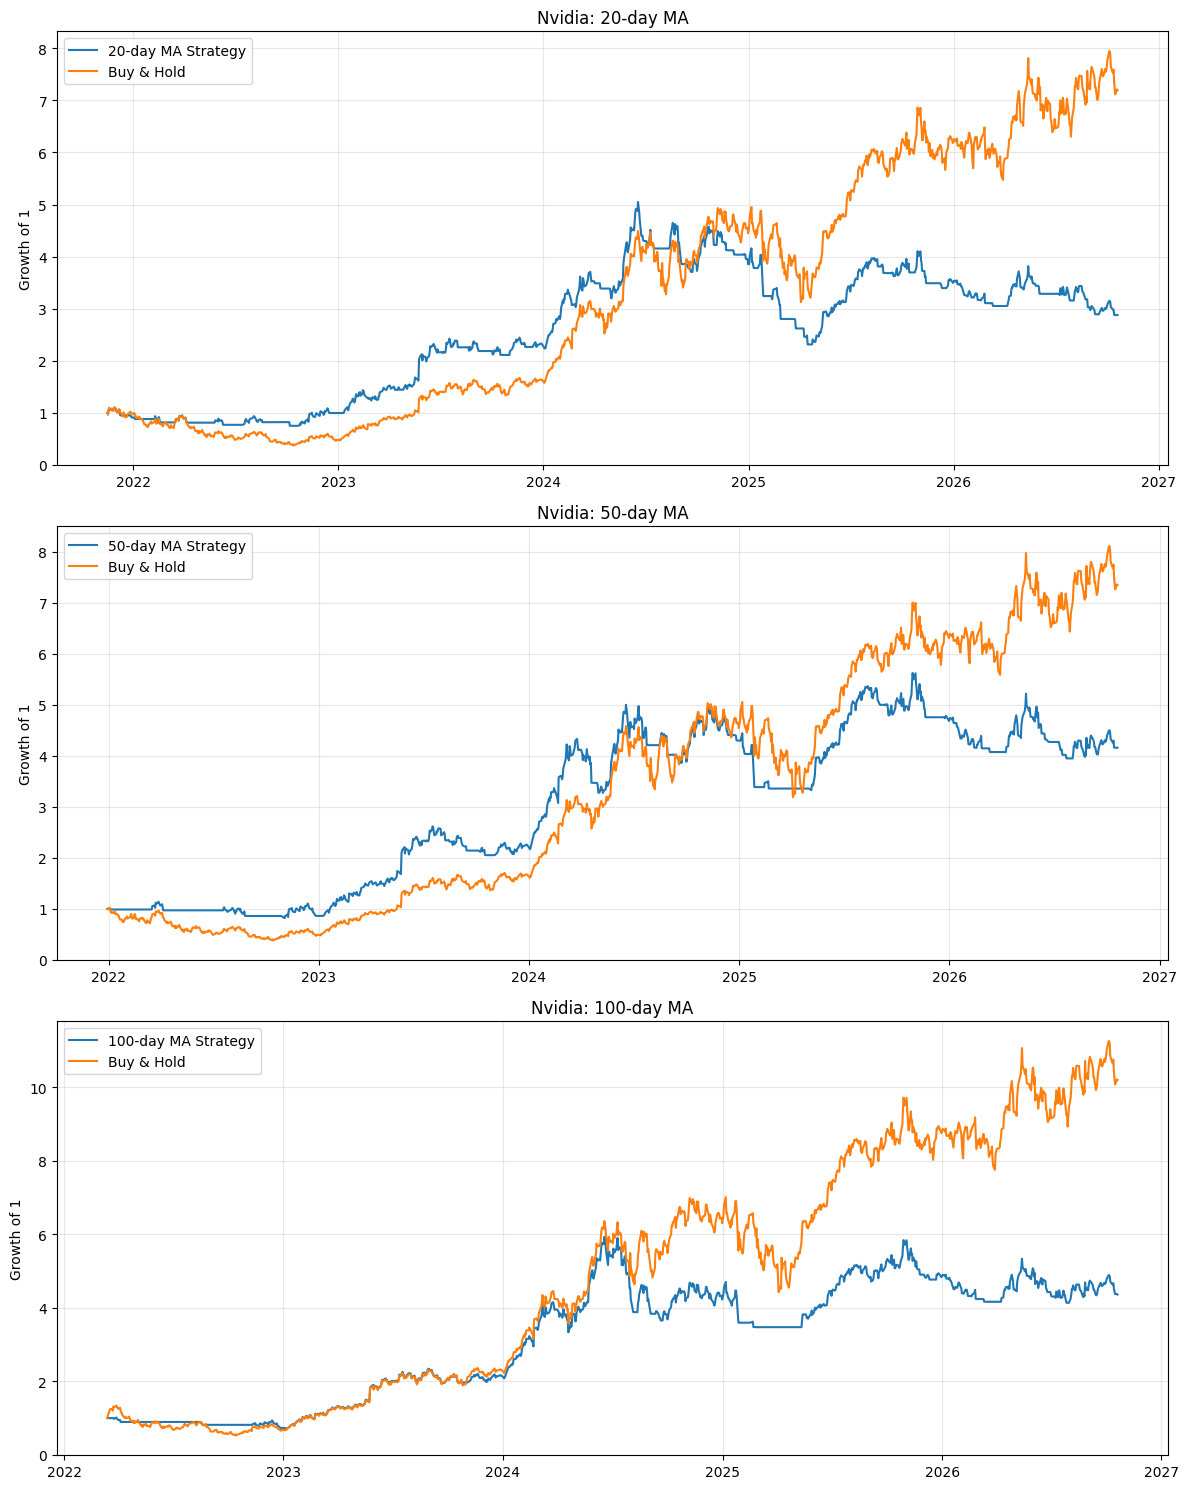

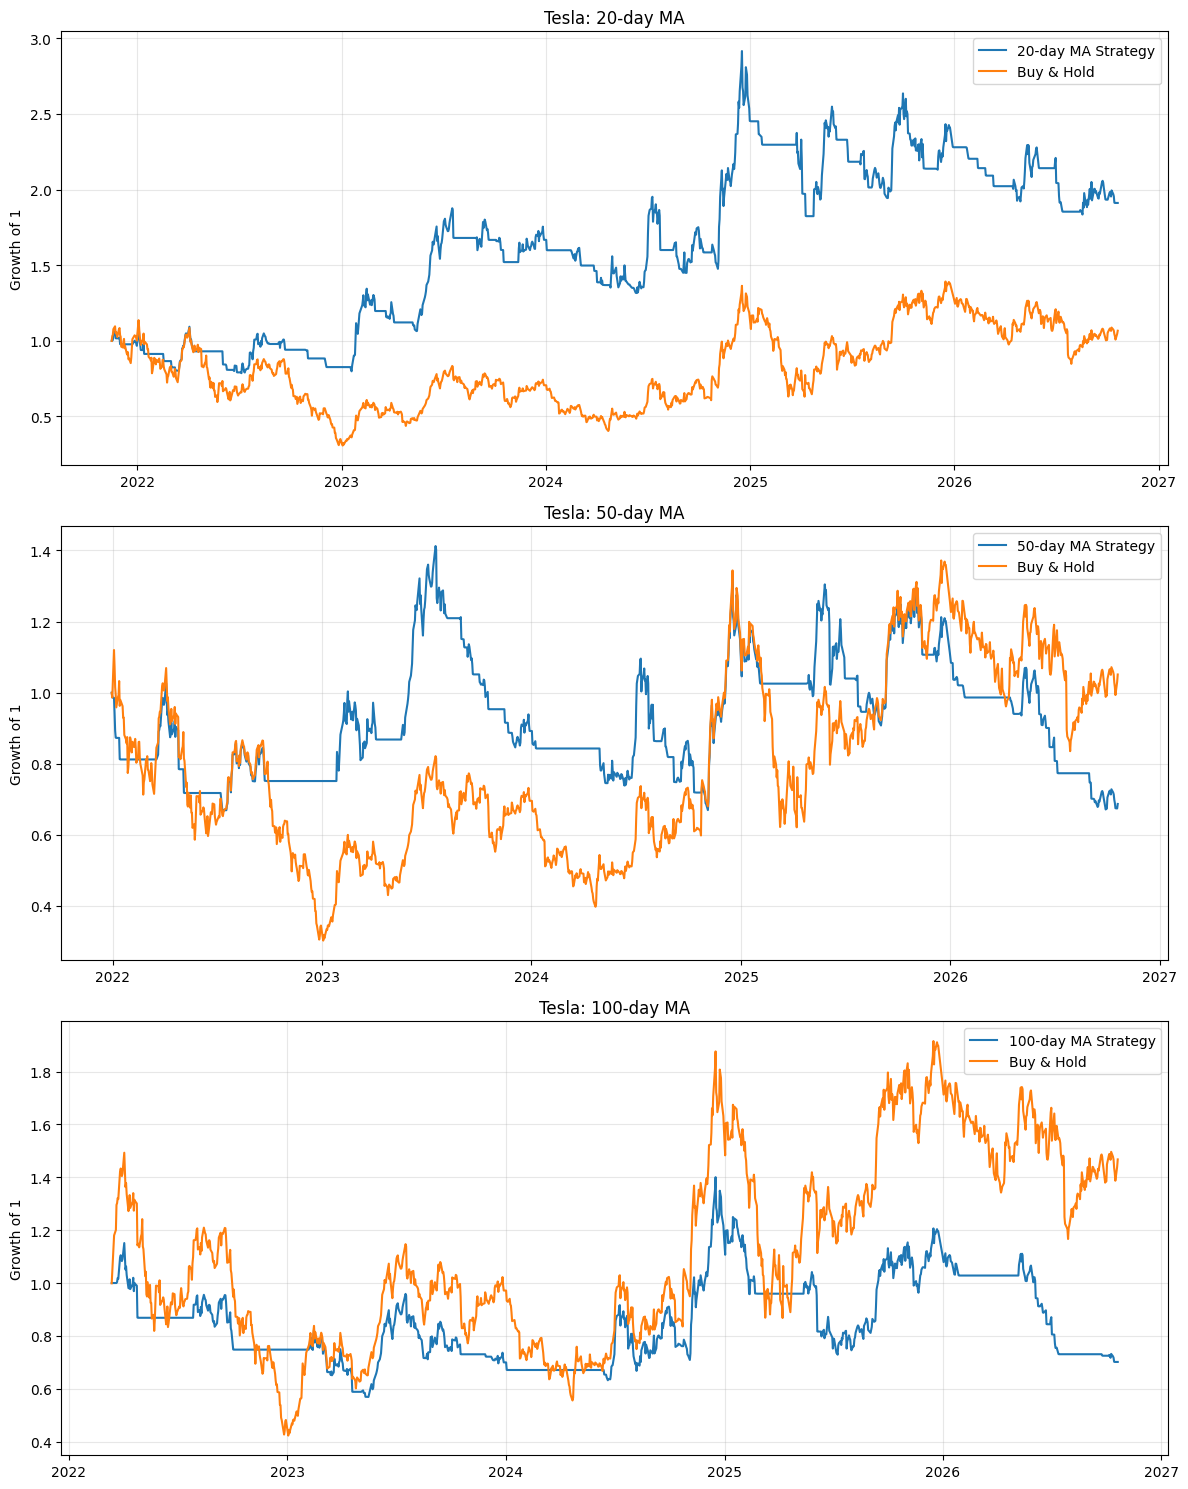

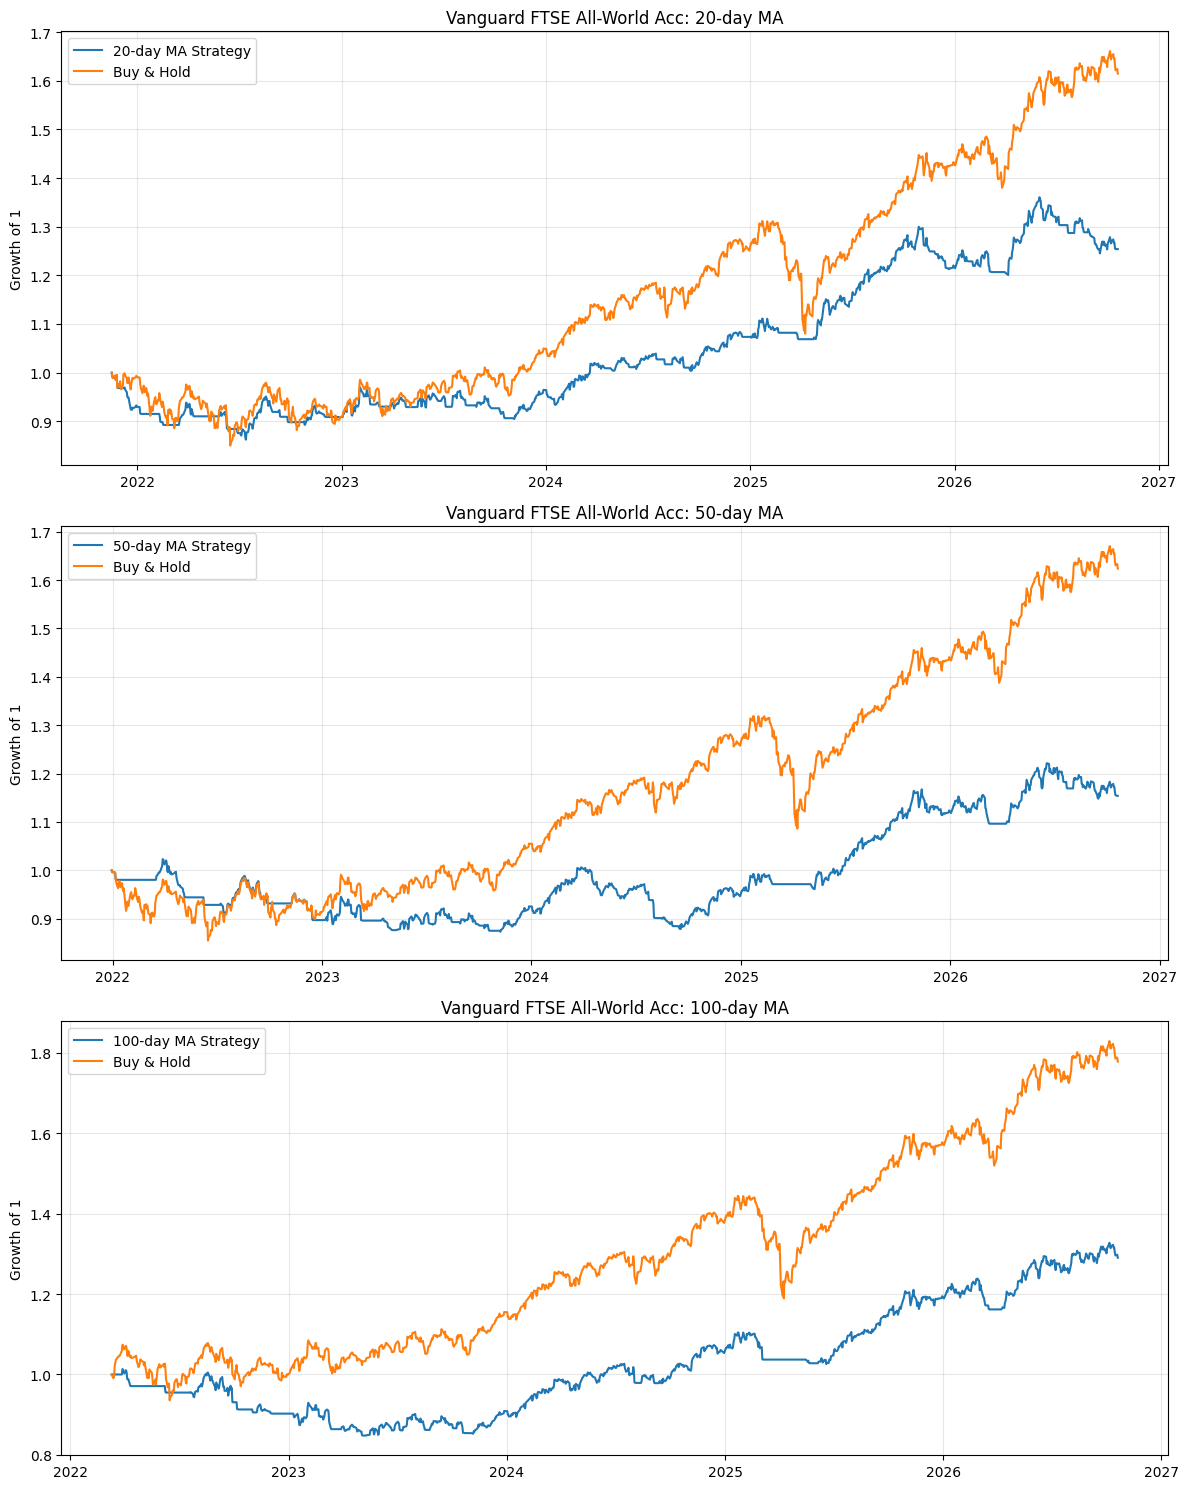

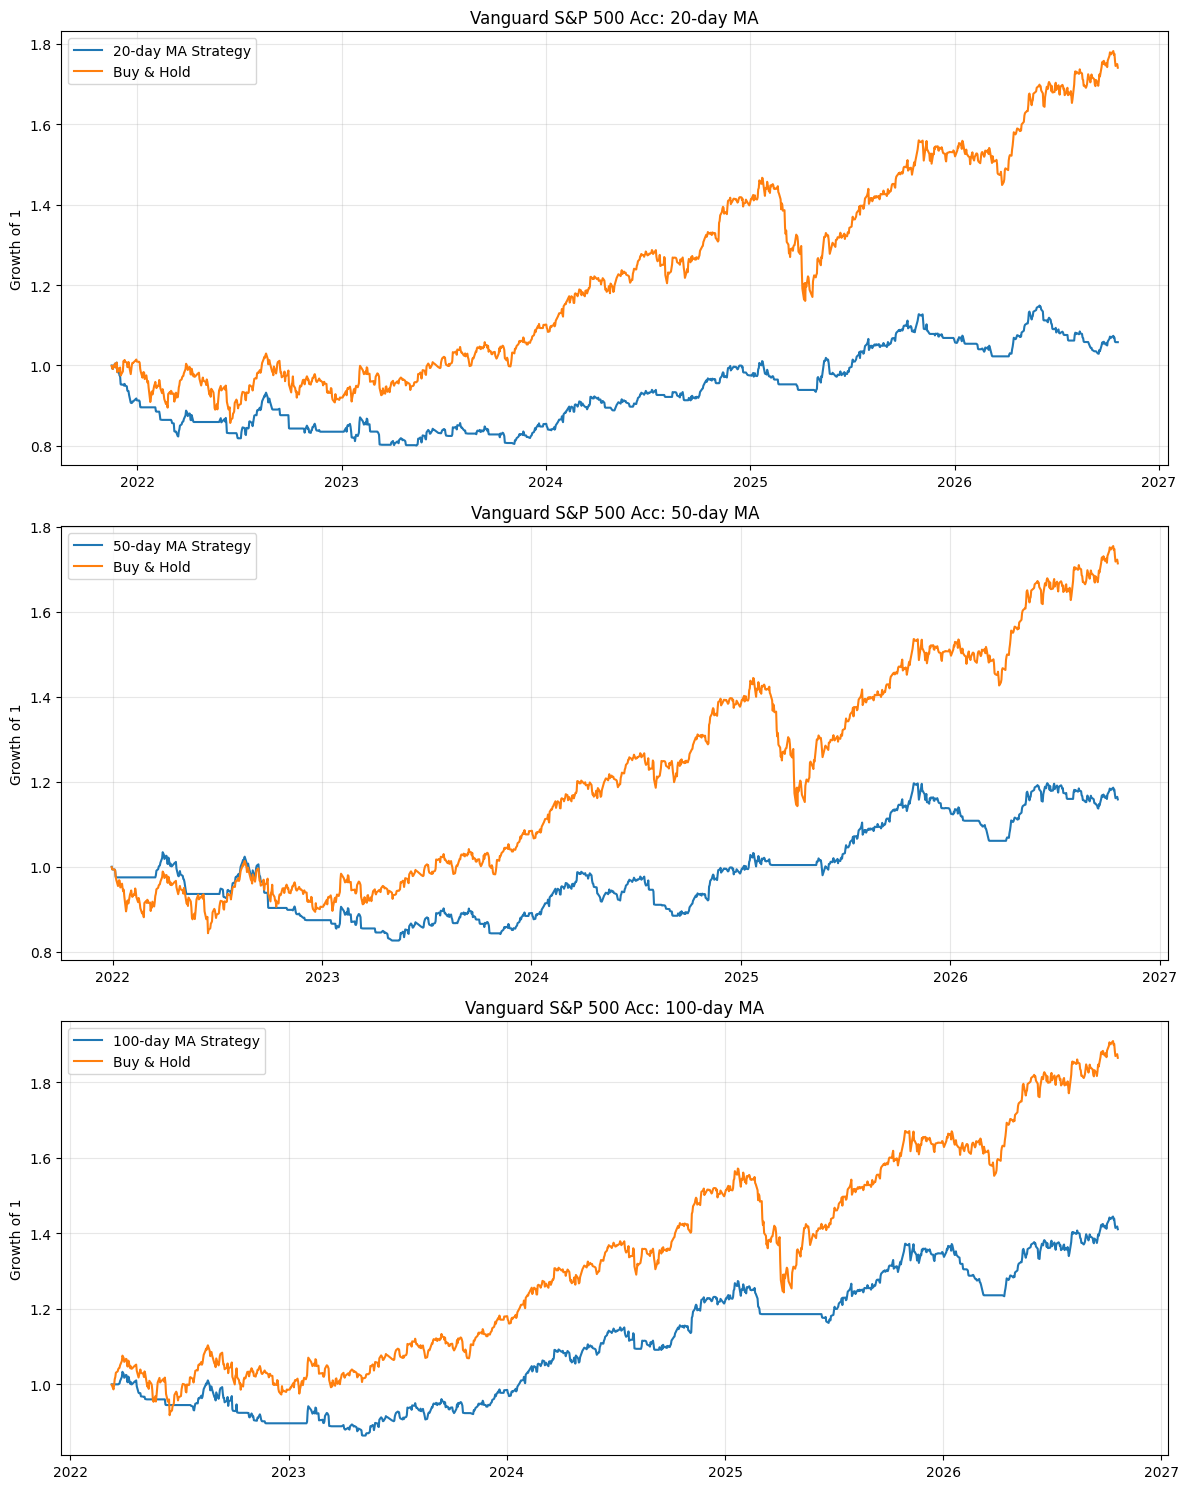

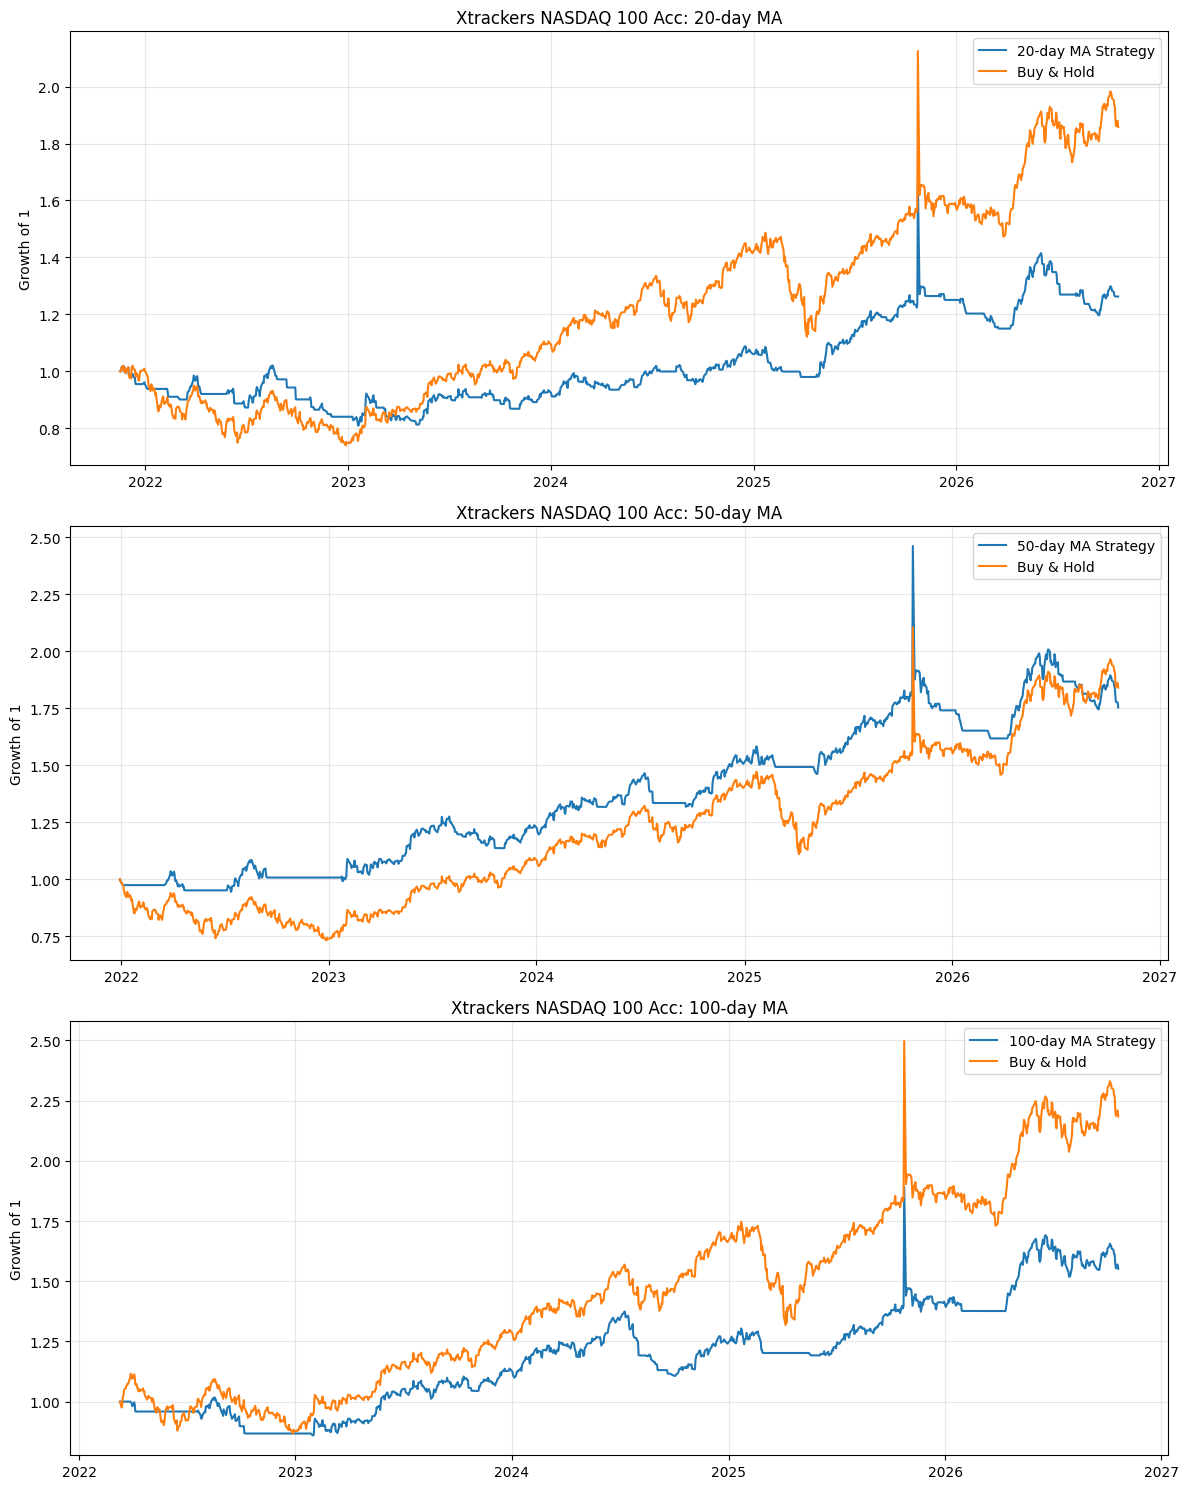

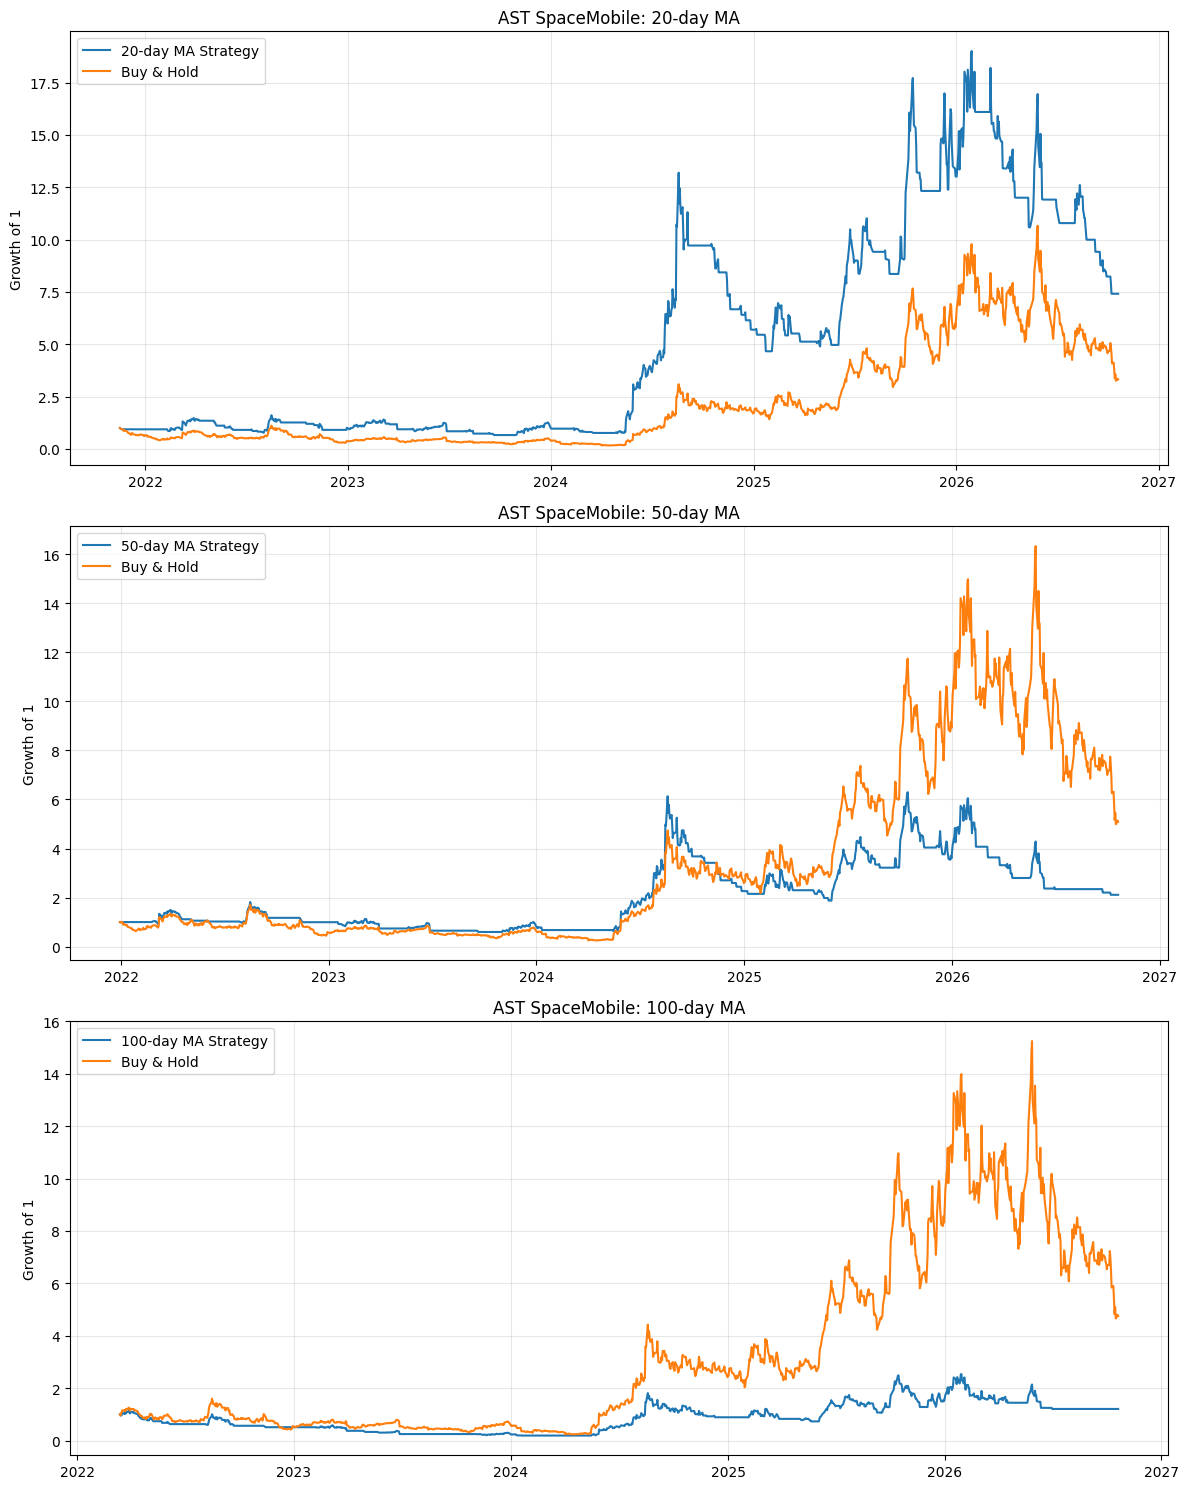

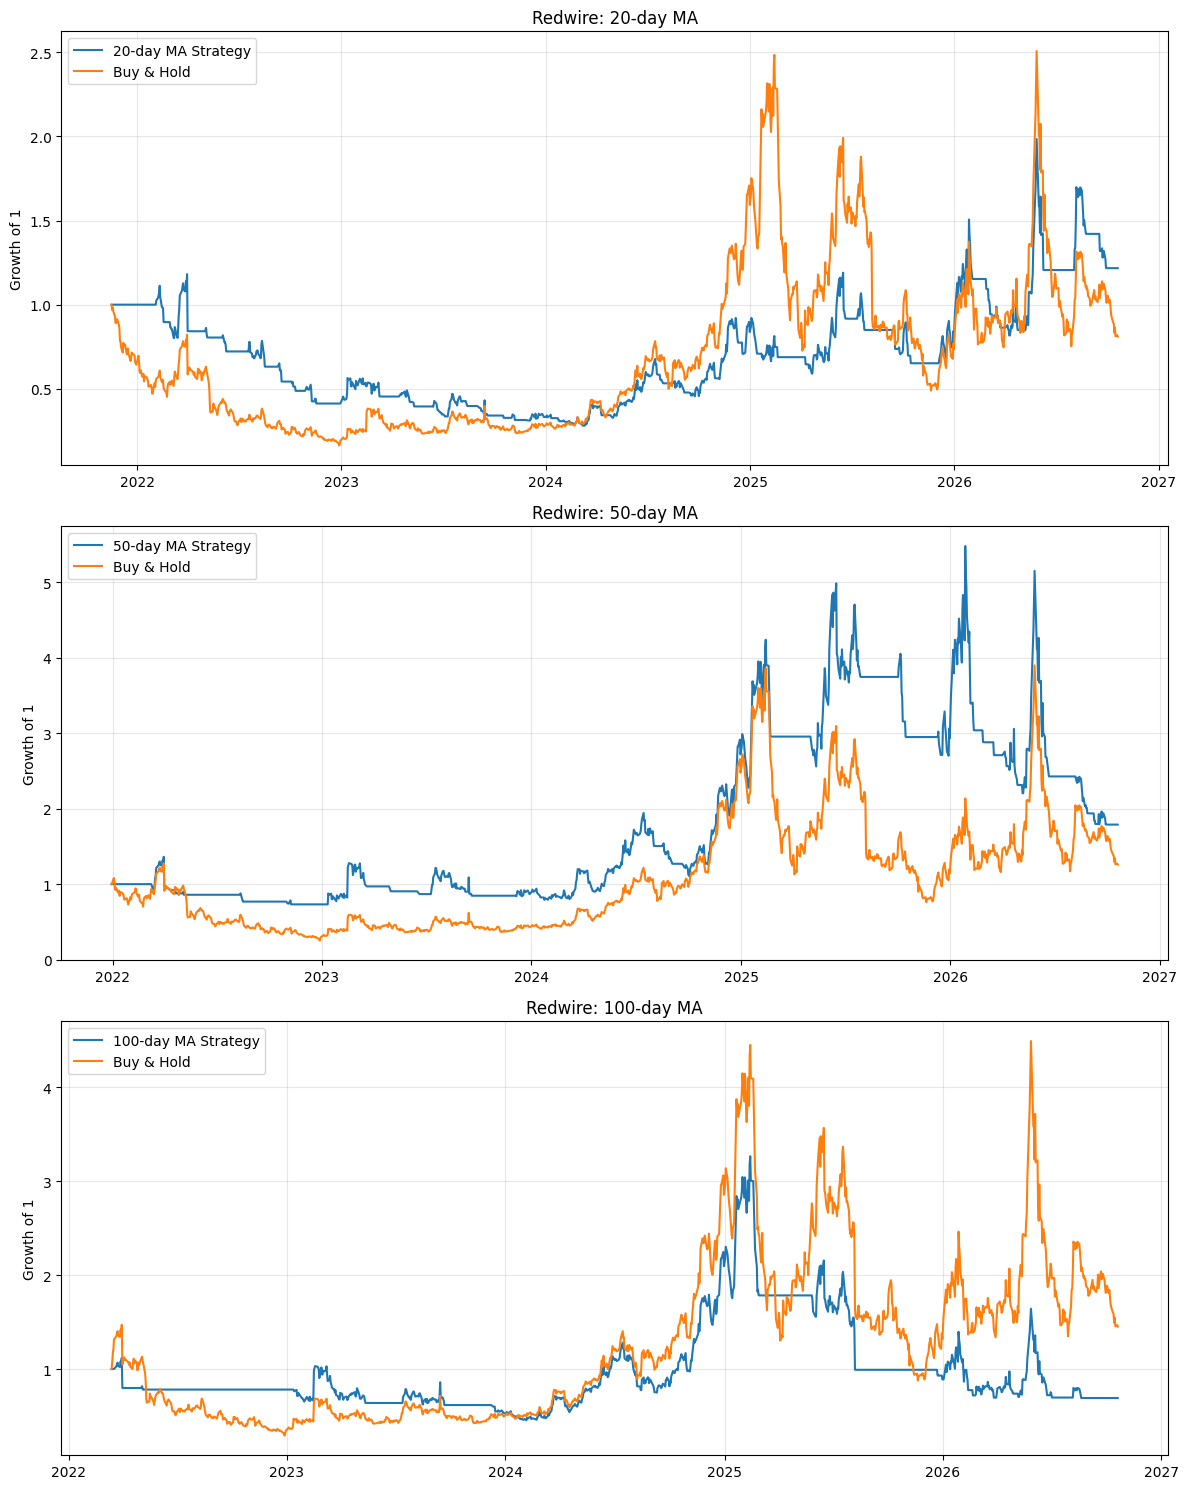


===== 需要檢查的標的 =====
SPDR S&P 500 Leaders Acc: SPPY.L
請核對代號、上市地點及 Yahoo Finance 數據是否可用。


In [6]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# 1. 股票及ETF清單
assets = {
    "Nvidia": "NVDA",
    "Tesla": "TSLA",
    "Vanguard FTSE All-World Acc": "VWRP.L",
    "Vanguard S&P 500 Acc": "VUAG.L",
    "Xtrackers NASDAQ 100 Acc": "XNAQ.L",
    "SPDR S&P 500 Leaders Acc": "SPPY.L",
    "AST SpaceMobile": "ASTS",
    "Redwire": "RDW",
}

# 2. 測試三種移動平均線週期
windows = [20, 50, 100]

# 假設每次進場或離場的單邊成本為0.1%
COST = 0.001

all_results = []
equity_curves = {}
failed = []

for name, ticker in assets.items():
    print(f"正在分析：{name} ({ticker})")

    try:
        data = yf.Ticker(ticker).history(
            period="5y",
            auto_adjust=True
        )

        if data.empty:
            failed.append((name, ticker))
            print("  沒有取得數據，跳過。")
            continue

        close = data["Close"].dropna()

        if len(close) < 120:
            failed.append((name, ticker))
            print("  歷史數據不足，跳過。")
            continue

        # 每個週期都使用相同的有效回測起點，
        # 以便與同一股票的買入持有作公平比較。
        for window in windows:
            ma = close.rolling(window).mean()
            valid = ma.notna()

            price = close.loc[valid]
            average = ma.loc[valid]

            # 股價高於平均線 = 持有訊號
            signal = (price > average).astype(int)

            # 延後一天執行訊號
            position = signal.shift(1).fillna(0)

            daily_return = price.pct_change().fillna(0)

            # 買入及賣出時都計入假設交易成本
            trades = position.diff().abs()
            trades.iloc[0] = position.iloc[0]
            trades = trades.fillna(0)

            strategy_return = (
                position * daily_return - trades * COST
            )

            # 買入持有：計入一次買入成本
            buy_hold_return = daily_return.copy()
            buy_hold_return.iloc[0] = (
                (1 + buy_hold_return.iloc[0]) * (1 - COST) - 1
            )

            strategy_equity = (
                1 + strategy_return
            ).cumprod()

            buy_hold_equity = (
                1 + buy_hold_return
            ).cumprod()

            # 總回報
            strategy_total = strategy_equity.iloc[-1] - 1
            hold_total = buy_hold_equity.iloc[-1] - 1

            # 最大回撤
            strategy_dd = (
                strategy_equity / strategy_equity.cummax() - 1
            )
            hold_dd = (
                buy_hold_equity / buy_hold_equity.cummax() - 1
            )

            # 年化回報
            years = (
                (price.index[-1] - price.index[0]).days / 365.25
            )

            strategy_cagr = (
                strategy_equity.iloc[-1] ** (1 / years) - 1
                if years > 0 else np.nan
            )

            hold_cagr = (
                buy_hold_equity.iloc[-1] ** (1 / years) - 1
                if years > 0 else np.nan
            )

            all_results.append({
                "Asset": name,
                "Ticker": ticker,
                "MA Days": window,
                "Strategy Return": strategy_total,
                "Buy & Hold Return": hold_total,
                "Strategy CAGR": strategy_cagr,
                "Buy & Hold CAGR": hold_cagr,
                "Strategy Max DD": strategy_dd.min(),
                "Buy & Hold Max DD": hold_dd.min(),
                "Trade Events": int(trades.sum()),
                "Start Date": str(price.index[0].date()),
                "End Date": str(price.index[-1].date()),
            })

            equity_curves[(name, window)] = pd.DataFrame({
                "MA Strategy": strategy_equity,
                "Buy & Hold": buy_hold_equity
            })

    except Exception as e:
        failed.append((name, ticker))
        print(f"  下載或計算失敗：{e}")

# 3. 顯示比較表
if all_results:
    results = pd.DataFrame(all_results)

    print("\n===== 全部標的及策略比較 =====")

    display(
        results.style.format({
            "Strategy Return": "{:.2%}",
            "Buy & Hold Return": "{:.2%}",
            "Strategy CAGR": "{:.2%}",
            "Buy & Hold CAGR": "{:.2%}",
            "Strategy Max DD": "{:.2%}",
            "Buy & Hold Max DD": "{:.2%}",
        })
    )

    # 4. 以年化回報排序，查看初步結果
    print("\n===== 按策略年化回報排序（僅供研究） =====")

    display(
        results.sort_values(
            "Strategy CAGR", ascending=False
        )[
            [
                "Asset", "MA Days",
                "Strategy CAGR",
                "Strategy Max DD",
                "Trade Events"
            ]
        ].style.format({
            "Strategy CAGR": "{:.2%}",
            "Strategy Max DD": "{:.2%}",
        })
    )

    # 5. 畫出每個標的的三種策略及買入持有曲線
    for name in assets:
        curves = [
            (window, equity_curves[(name, window)])
            for window in windows
            if (name, window) in equity_curves
        ]

        if not curves:
            continue

        fig, axes = plt.subplots(
            len(curves), 1, figsize=(12, 5 * len(curves))
        )

        if len(curves) == 1:
            axes = [axes]

        for ax, (window, curve) in zip(axes, curves):
            ax.plot(
                curve.index, curve["MA Strategy"],
                label=f"{window}-day MA Strategy"
            )
            ax.plot(
                curve.index, curve["Buy & Hold"],
                label="Buy & Hold"
            )
            ax.set_title(f"{name}: {window}-day MA")
            ax.set_ylabel("Growth of 1")
            ax.legend()
            ax.grid(alpha=0.3)

        plt.tight_layout()
        plt.show()

else:
    print("沒有成功取得任何標的的歷史數據。")

# 6. 列出下載失敗的標的
if failed:
    print("\n===== 需要檢查的標的 =====")
    for name, ticker in failed:
        print(f"{name}: {ticker}")
    print("請核對代號、上市地點及 Yahoo Finance 數據是否可用。")

最近5個交易日的收市價：


Ticker,NVDA,TSLA
Date,,
2026-10-14,221.300003,367.160004
2026-10-15,217.229996,362.440002
2026-10-16,214.130005,354.720001
2026-10-19,217.089996,368.059998
2026-10-20,217.315002,374.484985


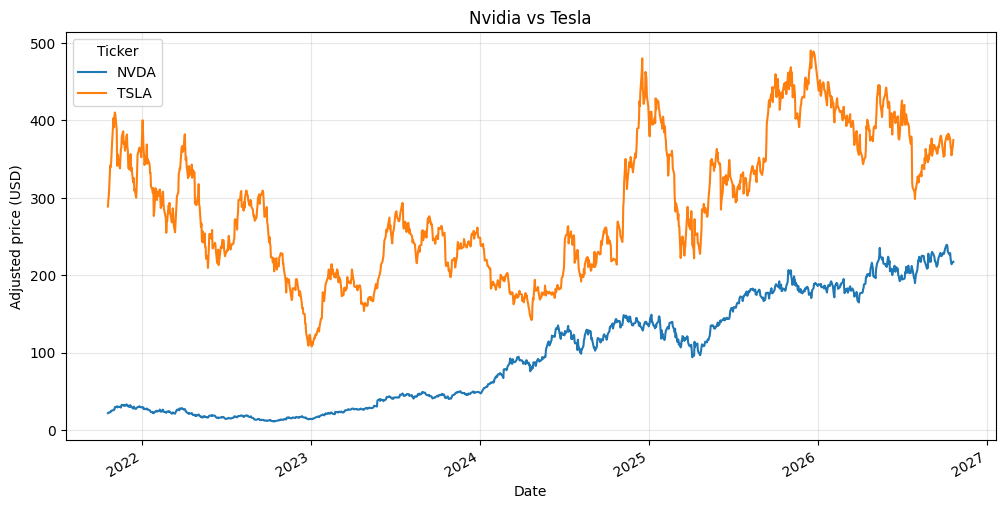

In [3]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

stocks = ["NVDA", "TSLA"]

prices = yf.download(
    stocks,
    period="5y",
    auto_adjust=True,
    progress=False
)

close = prices["Close"]

print("最近5個交易日的收市價：")
display(close.tail())

close.plot(figsize=(12, 6), title="Nvidia vs Tesla")
plt.ylabel("Adjusted price (USD)")
plt.grid(alpha=0.3)
plt.show()